In [1]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector 
from math import pi
import numpy as np
from random import random
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

sim = AerSimulator()

In [2]:
def rename(counts):
    new_counts = {}
    trans = {"00": "00","10": "01", "01": "10","11": "11"}
    for key in counts:
        new_counts[trans[key]] = counts[key]
    return new_counts

In [23]:
def run_circuit(alpha, beta, xi, phi_p, phi_m, kappa_2, zeta, omega_p, omega_m, kappa_m2, runs):
    circ = QuantumCircuit(2,2)
    circ.initialize([alpha,beta],0)
    circ.ry(-2*xi,0)
    circ.ry(2*phi_p,1)
    circ.cry(2*phi_m - 2*phi_p,0,1)
    circ.ry(2*xi,0)
    circ.measure(1,0)
    with circ.if_test((circ.clbits[0], 1)):
        circ.ry(2*kappa_2,0)
        circ.ry(-2*zeta,0)
        circ.ry(2*omega_p,1)
        circ.cry(2*omega_m - 2*omega_p,0,1)
        circ.ry(2*zeta,0)
    circ.measure(1,1)
    with circ.if_test((circ.clbits[1], 1)):
        circ.ry(2*kappa_m2,0)
    display(circ.draw('mpl'))
    job = sim.run(circ, shots=runs)
    out = job.result().get_counts()
    out = rename(out)
    for i in out:
        out[i] /= runs
    return out



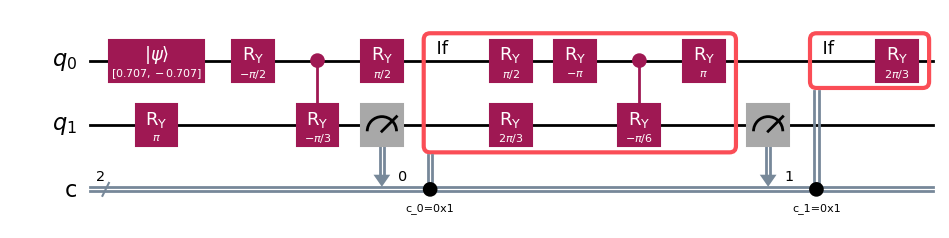

In [26]:
statistics = run_circuit(1/np.sqrt(2),-1/np.sqrt(2),pi/4,pi/2,pi/3,pi/4,pi/2,pi/3,pi/4,pi/3, 10000)


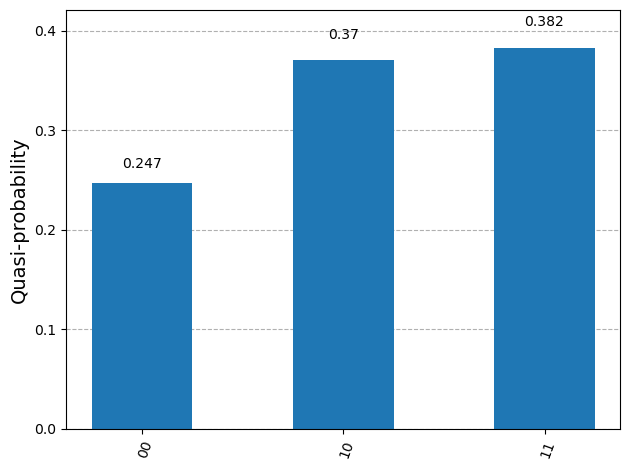

In [27]:
plot_histogram(statistics)